# 04_decompose_vrp_channels

Force repo root

In [1]:
from pathlib import Path
import os

p = Path.cwd().resolve()
while not (p / ".git").exists() and p != p.parent:
    p = p.parent
os.chdir(p)

print("CWD set to repo root:", Path.cwd())


CWD set to repo root: C:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc


## Part A: Event-study plots for IV and forward RV

Load daily dataset and meeting dates

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

daily = pd.read_parquet("data/processed/vrp_vix_daily.parquet")
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.set_index("date").sort_index()

meet = pd.read_parquet("data/processed/meetings_vrp_usmpd.parquet")
meet["event_date"] = pd.to_datetime(meet["event_date"])
event_dates = pd.to_datetime(meet["event_date"].unique())

print("Daily sample:", daily.index.min(), daily.index.max(), len(daily))
print("Meeting events:", len(event_dates))


Daily sample: 2016-02-08 00:00:00 2026-01-05 00:00:00 2492
Meeting events: 78


Helper: trading-day event study

In [3]:
def event_study(daily_series: pd.Series, event_dates, W=5):
    idx = daily_series.index
    offs = np.arange(-W, W+1)

    rows = []
    used = 0

    for d in pd.to_datetime(event_dates):
        # align to next trading day if needed
        if d not in idx:
            pos = idx.searchsorted(d)
            if pos >= len(idx):
                continue
            d = idx[pos]

        pos = idx.get_loc(d)
        if pos - W < 0 or pos + W >= len(idx):
            continue

        rows.append(daily_series.iloc[pos-W:pos+W+1].values)
        used += 1

    mat = np.vstack(rows)
    mean = mat.mean(axis=0)
    se = mat.std(axis=0, ddof=1) / np.sqrt(mat.shape[0])
    return offs, mean, se, used


Plot IVAR around meetings (t-5 to t+5)

IV event-study events used: 78


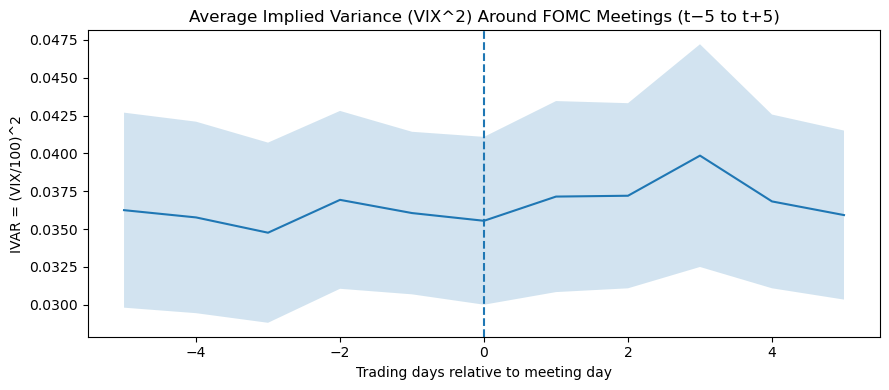

Saved: reports/figures/fomc_event_iv_tminus5_tplus5.png


In [4]:
Path("reports/figures").mkdir(parents=True, exist_ok=True)

offs, mean_iv, se_iv, n_used = event_study(daily["iv"], event_dates, W=5)
print("IV event-study events used:", n_used)

plt.figure(figsize=(9,4))
plt.plot(offs, mean_iv)
plt.fill_between(offs, mean_iv - 1.96*se_iv, mean_iv + 1.96*se_iv, alpha=0.2)
plt.axvline(0, linestyle="--")
plt.title("Average Implied Variance (VIX^2) Around FOMC Meetings (t−5 to t+5)")
plt.xlabel("Trading days relative to meeting day")
plt.ylabel("IVAR = (VIX/100)^2")
plt.tight_layout()
plt.savefig("reports/figures/fomc_event_iv_tminus5_tplus5.png", dpi=200)
plt.show()

print("Saved: reports/figures/fomc_event_iv_tminus5_tplus5.png")


Plot forward realized variance around meetings

RV_fwd event-study events used: 78


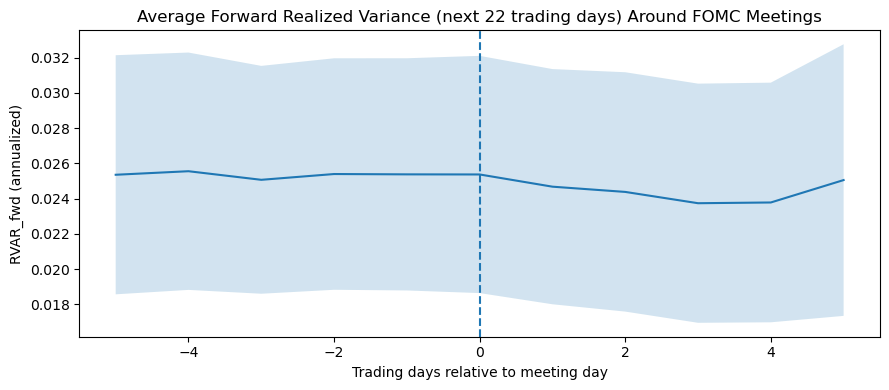

Saved: reports/figures/fomc_event_rv_fwd_tminus5_tplus5.png


In [5]:
offs, mean_rv, se_rv, n_used = event_study(daily["rv_fwd"], event_dates, W=5)
print("RV_fwd event-study events used:", n_used)

plt.figure(figsize=(9,4))
plt.plot(offs, mean_rv)
plt.fill_between(offs, mean_rv - 1.96*se_rv, mean_rv + 1.96*se_rv, alpha=0.2)
plt.axvline(0, linestyle="--")
plt.title("Average Forward Realized Variance (next 22 trading days) Around FOMC Meetings")
plt.xlabel("Trading days relative to meeting day")
plt.ylabel("RVAR_fwd (annualized)")
plt.tight_layout()
plt.savefig("reports/figures/fomc_event_rv_fwd_tminus5_tplus5.png", dpi=200)
plt.show()

print("Saved: reports/figures/fomc_event_rv_fwd_tminus5_tplus5.png")


## Part B: Meeting regressions for IV and forward RV

Load the meeting dataset with tone and rebuild controls

In [6]:
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col

meet2 = pd.read_parquet("data/processed/meetings_vrp_usmpd_tone.parquet")
meet2["event_date"] = pd.to_datetime(meet2["event_date"])
meet2["Date"] = pd.to_datetime(meet2["Date"])

# rebuild controls from daily (pre-event)
h = 22
daily["rv_back_22"] = daily["ret2"].rolling(h).sum().shift(1) * (252 / h)
daily["iv_lag1"] = daily["iv"].shift(1)

meet4 = meet2.merge(
    daily[["iv_lag1","rv_back_22"]].reset_index().rename(columns={"date":"event_date"}),
    on="event_date",
    how="left"
)

print(meet4[["iv","rv_fwd","vrp","surprise_pc1","tone_net","unc_share","iv_lag1","rv_back_22"]].isna().sum())
print("Rows:", len(meet4))


iv              0
rv_fwd          0
vrp             0
surprise_pc1    0
tone_net        0
unc_share       0
iv_lag1         0
rv_back_22      0
dtype: int64
Rows: 78


Regression helper

In [7]:
def ols_hc1(df, y, xcols):
    X = sm.add_constant(df[xcols].astype(float))
    yv = df[y].astype(float)
    return sm.OLS(yv, X, missing="drop").fit(cov_type="HC1")

controls = ["iv_lag1", "rv_back_22"]


Meeting regressions with DV = IVAR

In [9]:
m_iv_A = ols_hc1(meet4, "iv", ["surprise_pc1"] + controls)
m_iv_B = ols_hc1(meet4, "iv", ["surprise_pc1", "tone_net"] + controls)
m_iv_C = ols_hc1(meet4, "iv", ["surprise_pc1", "unc_share"] + controls)

tab_iv = summary_col(
    [m_iv_A, m_iv_B, m_iv_C],
    stars=True,
    float_format="%.4f",
    model_names=["IV~Surp+Ctrls", "IV~Surp+Tone+Ctrls", "IV~Surp+Unc+Ctrls"],
    info_dict={"N": lambda x: f"{int(x.nobs)}", "R2": lambda x: f"{x.rsquared:.3f}"}
)

print(tab_iv)

Path("reports/tables").mkdir(parents=True, exist_ok=True)
Path("reports/tables/reg_iv_surprise_tone_controls.tex").write_text(tab_iv.as_latex(), encoding="utf-8")
print("Saved: reports/tables/reg_iv_surprise_tone_controls.tex")



               IV~Surp+Ctrls IV~Surp+Tone+Ctrls IV~Surp+Unc+Ctrls
-----------------------------------------------------------------
const          0.0029        0.0045*            0.0019           
               (0.0018)      (0.0023)           (0.0021)         
surprise_pc1   0.0007        0.0007             0.0007           
               (0.0009)      (0.0009)           (0.0008)         
iv_lag1        0.9629***     0.9601***          0.9681***        
               (0.1053)      (0.1045)           (0.1013)         
rv_back_22     -0.0836       -0.0938            -0.0857          
               (0.0729)      (0.0798)           (0.0716)         
tone_net                     -0.2191                             
                             (0.1903)                            
unc_share                                       0.0725           
                                                (0.2019)         
R-squared      0.7592        0.7625             0.7596           
R-squared

Meeting regressions with DV = forward realized variance

In [10]:
m_rv_A = ols_hc1(meet4, "rv_fwd", ["surprise_pc1"] + controls)
m_rv_B = ols_hc1(meet4, "rv_fwd", ["surprise_pc1", "tone_net"] + controls)
m_rv_C = ols_hc1(meet4, "rv_fwd", ["surprise_pc1", "unc_share"] + controls)

tab_rv = summary_col(
    [m_rv_A, m_rv_B, m_rv_C],
    stars=True,
    float_format="%.4f",
    model_names=["RVfwd~Surp+Ctrls", "RVfwd~Surp+Tone+Ctrls", "RVfwd~Surp+Unc+Ctrls"],
    info_dict={"N": lambda x: f"{int(x.nobs)}", "R2": lambda x: f"{x.rsquared:.3f}"}
)

print(tab_rv)

Path("reports/tables/reg_rv_fwd_surprise_tone_controls.tex").write_text(tab_rv.as_latex(), encoding="utf-8")
print("Saved: reports/tables/reg_rv_fwd_surprise_tone_controls.tex")



               RVfwd~Surp+Ctrls RVfwd~Surp+Tone+Ctrls RVfwd~Surp+Unc+Ctrls
--------------------------------------------------------------------------
const          0.0055           0.0066                0.0063              
               (0.0037)         (0.0064)              (0.0088)            
surprise_pc1   -0.0003          -0.0003               -0.0003             
               (0.0016)         (0.0016)              (0.0017)            
iv_lag1        0.5353***        0.5334***             0.5313***           
               (0.1427)         (0.1413)              (0.1573)            
rv_back_22     0.0212           0.0142                0.0228              
               (0.0970)         (0.1008)              (0.0964)            
tone_net                        -0.1502                                   
                                (0.7708)                                  
unc_share                                             -0.0546             
                        

Add captions automatically

In [11]:
from pathlib import Path

def add_caption_label(tex_path, caption, label):
    tex = Path(tex_path).read_text(encoding="utf-8")
    tex = tex.replace(r"\caption{}", rf"\caption{{{caption}}}")
    tex = tex.replace(r"\label{}",   rf"\label{{{label}}}")
    Path(tex_path).write_text(tex, encoding="utf-8")

add_caption_label(
    "reports/tables/reg_iv_surprise_tone_controls.tex",
    "Meeting-level regressions with implied variance (IVAR) as the dependent variable.",
    "tab:meet_iv_controls"
)

add_caption_label(
    "reports/tables/reg_rv_fwd_surprise_tone_controls.tex",
    "Meeting-level regressions with forward realized variance as the dependent variable.",
    "tab:meet_rv_controls"
)
